In [5]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import time

from sklearn.datasets import make_moons
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.metrics import accuracy_score, classification_report

X, y = make_moons(n_samples=600, noise=0.25, random_state=42)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=42, stratify=y
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))
print("Features:", X.shape[1])


Training samples: 420
Testing samples: 180
Features: 2


In [6]:

pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("svm", SVC(kernel="rbf"))
])

print(pipeline)


Pipeline(steps=[('scaler', StandardScaler()), ('svm', SVC())])


In [7]:

param_grid = {
    "svm__C": [0.01, 0.1, 1, 10, 100],
    "svm__gamma": [0.001, 0.01, 0.1, 1, 10]
}

grid_search = GridSearchCV(
    pipeline,
    param_grid,
    cv=5,
    scoring="accuracy",
    n_jobs=-1
)

start = time.perf_counter()
grid_search.fit(X_train, y_train)
grid_time = time.perf_counter() - start

print("Best parameters:", grid_search.best_params_)
print("Best CV accuracy:", round(grid_search.best_score_, 4))
print("Grid Search Time:", round(grid_time, 4), "seconds")


Best parameters: {'svm__C': 10, 'svm__gamma': 1}
Best CV accuracy: 0.9405
Grid Search Time: 6.5824 seconds


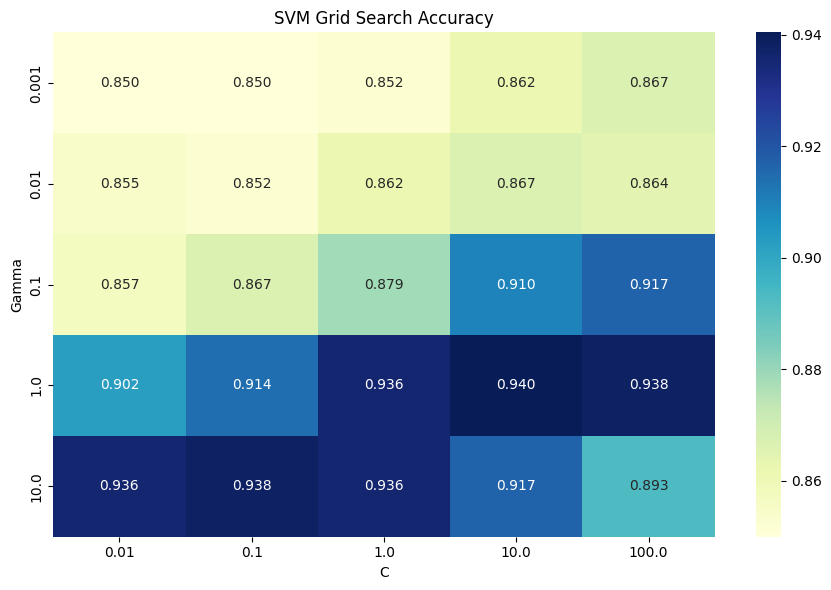

In [8]:

results = pd.DataFrame(grid_search.cv_results_)

heatmap_data = results.pivot(
    index="param_svm__gamma",
    columns="param_svm__C",
    values="mean_test_score"
)

plt.figure(figsize=(9, 6))

sns.heatmap(
    heatmap_data,
    annot=True,
    fmt=".3f",
    cmap="YlGnBu"
)

plt.title("SVM Grid Search Accuracy")
plt.xlabel("C")
plt.ylabel("Gamma")
plt.tight_layout()
plt.show()


In [9]:

linear_pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("svm", SVC(kernel="linear", C=1))
])

start = time.perf_counter()
linear_pipeline.fit(X_train, y_train)
linear_time = time.perf_counter() - start

linear_pred = linear_pipeline.predict(X_test)
rbf_pred = grid_search.predict(X_test)

print("Linear SVM Accuracy:", accuracy_score(y_test, linear_pred))
print("RBF SVM Accuracy:", accuracy_score(y_test, rbf_pred))
print("Linear SVM Training Time:", round(linear_time, 4))


Linear SVM Accuracy: 0.8555555555555555
RBF SVM Accuracy: 0.9333333333333333
Linear SVM Training Time: 0.0502


In [11]:


models = {
    "RBF SVM": grid_search.best_estimator_,
    "Linear SVM": linear_pipeline,
    "Random Forest": RandomForestClassifier(n_estimators=100, random_state=42),
    "Gradient Boosting": GradientBoostingClassifier(n_estimators=100, random_state=42)
}

comparison = []

for name, model in models.items():
    start = time.perf_counter()
    model.fit(X_train, y_train)
    training_time = time.perf_counter() - start

    predictions = model.predict(X_test)
    accuracy = accuracy_score(y_test, predictions)

    comparison.append({
        "Model": name,
        "Accuracy": accuracy,
        "Training Time (s)": training_time
    })

comparison_df = pd.DataFrame(comparison)

print(comparison_df)



               Model  Accuracy  Training Time (s)
0            RBF SVM  0.933333           0.035336
1         Linear SVM  0.855556           0.034405
2      Random Forest  0.933333           1.155978
3  Gradient Boosting  0.911111           0.683116


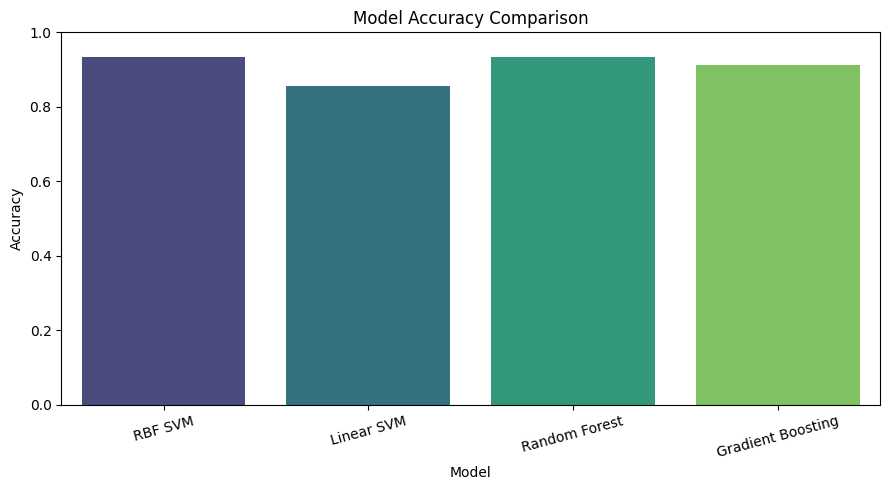

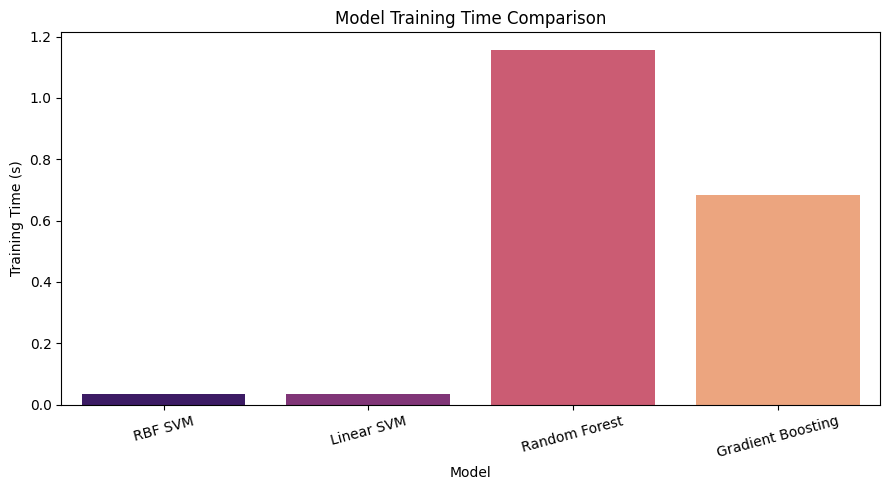

In [12]:

plt.figure(figsize=(9, 5))

sns.barplot(
    data=comparison_df,
    x="Model",
    y="Accuracy",
    hue="Model",
    palette="viridis",
    legend=False
)

plt.title("Model Accuracy Comparison")
plt.ylim(0, 1)
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

plt.figure(figsize=(9, 5))

sns.barplot(
    data=comparison_df,
    x="Model",
    y="Training Time (s)",
    hue="Model",
    palette="magma",
    legend=False
)

plt.title("Model Training Time Comparison")
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()


In [13]:


print("FINAL RESULTS")
print("=" * 40)

print("Best C:", grid_search.best_params_["svm__C"])
print("Best gamma:", grid_search.best_params_["svm__gamma"])
print("Best Cross-Validation Accuracy:", round(grid_search.best_score_, 4))
print("Grid Search Time:", round(grid_time, 4), "seconds")

print("\nModel Comparison:")
print(comparison_df.to_string(index=False))

best_model_row = comparison_df.loc[
    comparison_df["Accuracy"].idxmax()
]

print("\nHighest Test Accuracy:", best_model_row["Model"])


FINAL RESULTS
Best C: 10
Best gamma: 1
Best Cross-Validation Accuracy: 0.9405
Grid Search Time: 6.5824 seconds

Model Comparison:
            Model  Accuracy  Training Time (s)
          RBF SVM  0.933333           0.035336
       Linear SVM  0.855556           0.034405
    Random Forest  0.933333           1.155978
Gradient Boosting  0.911111           0.683116

Highest Test Accuracy: RBF SVM
